# 1.03. Множественное тестирование гипотез

**План занятия**

1. Задачка про «экстрасенсов» и суть проблемы множественных сравнений.
2. FWER и FDR: определения, формулы, симуляции и чем они отличаются.
3. Поправки: Бонферрони, Холм, Шидак, Бенджамини–Хохберг, Бенджамини–Йекутиели.
4. Какой метод выбрать: сравнение на симуляциях и шпаргалка.
5. Дизайн эксперимента: как скорректировать размер выборки и распределить трафик по группам.
6. Решения на нескольких метриках: фреймворк Spotify.

## Библиотеки

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ipywidgets import FloatSlider, IntSlider, interact
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower
from tqdm import tqdm

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Один метод на всех графиках имеет один цвет и один маркер
METHOD_STYLE = {
    'Без поправки': ('#8a8a85', 'o'),
    'Бонферрони': ('#2a78d6', 's'),
    'Холм': ('#eb6834', '^'),
    'Шидак': ('#1baf7a', 'D'),
    'BH': ('#eda100', 'v'),
    'BY': ('#e87ba4', 'P'),
}
REAL_COLOR, NULL_COLOR = '#2a78d6', '#eb6834'  # гипотезы с реальным эффектом и без него
REFERENCE_COLOR = '#52514e'                    # линии α и β

## Задачка

Начнём с задачки. Это учебный пример, известный как **парадокс Райна**: он назван в честь парапсихолога Джозефа Бэнкса Райна (Joseph Banks Rhine), изучавшего экстрасенсорное восприятие. Настоящие опыты Райна были устроены сложнее, а числа ниже условные.

Каждый испытуемый должен угадать цвет 10 карт подряд, причём каждая карта с равной вероятностью оказывается одного из двух цветов. Исследователь считает, что случайно угадать 9 или 10 карт из десяти почти невозможно, поэтому такой результат будет свидетельством экстрасенсорных способностей.

Из тысячи испытуемых 12 человек угадали 9 карт из 10, а двое угадали все 10. Однако при повторной проверке способности этих людей не подтвердились.

1. **Какова вероятность случайно угадать 9 или 10 карт из десяти?**
2. **Первый этап выявил целых 14 человек, хотя вероятность пройти его случайно мала. Почему второй этап не подтвердил их способности?**

### Ответы

**1. Какова вероятность случайно угадать 9 или 10 карт из десяти?**

Пусть $X$ — число карт, угаданных одним человеком. Без экстрасенсорных способностей каждая карта угадывается с вероятностью $p = 0.5$, поэтому $X \sim \text{Bin}(n=10, p=0.5)$.

1. Вероятность угадать ровно $k$ карт: $P(X = k) = \binom{10}{k} (0.5)^{10}$.

2. Вероятность угадать **не менее 9 карт**: $P(X \geq 9) = P(X=9) + P(X=10)$.

3. Считаем:

   $P(X=9) = \binom{10}{9} (0.5)^{10} = \frac{10}{1024} \approx 0.00977$

   $P(X=10) = \binom{10}{10} (0.5)^{10} = \frac{1}{1024} \approx 0.00098$

   $P(X \geq 9) = \frac{11}{1024} \approx 0.0107$

То есть вероятность случайно угадать 9 или 10 карт из 10 составляет **примерно 1.07%**.

**2. Почему второй этап не подтвердил их способности?**

Вероятность 1% мала для одного человека, но испытуемых тысяча. Посчитаем, чего ждать от тысячи людей, которые просто угадывают.

Вероятность для одного человека:         0.01074
Ожидаем удачливых среди 1000:           10.7
Вероятность, что удачливых не будет:     2.0e-05
Вероятность хотя бы одного удачливого:   0.99998
Вероятность найти 14 и больше:             0.194
Ожидаем повторивших успех из 14:          0.15


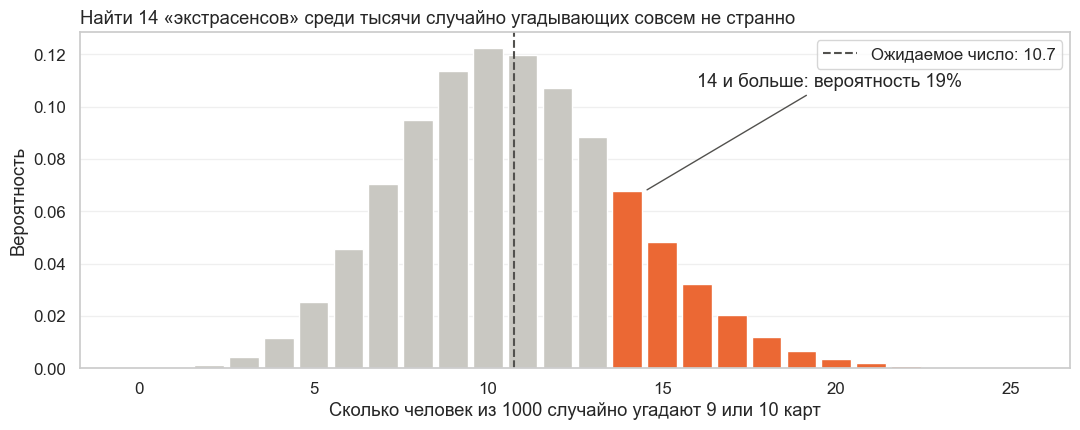

In [2]:
p_single = stats.binom.sf(8, 10, 0.5)  # P(X >= 9) = 11/1024
n_people = 1000
n_found = 14

expected_lucky = n_people * p_single
p_nobody = (1 - p_single) ** n_people
p_at_least_found = stats.binom.sf(n_found - 1, n_people, p_single)
expected_retest = n_found * p_single
p_any_retest = 1 - (1 - p_single) ** n_found

print(f"Вероятность для одного человека:         {p_single:.5f}")
print(f"Ожидаем удачливых среди {n_people}:           {expected_lucky:.1f}")
print(f"Вероятность, что удачливых не будет:     {p_nobody:.1e}")
print(f"Вероятность хотя бы одного удачливого:   {1 - p_nobody:.5f}")
print(f"Вероятность найти {n_found} и больше:             {p_at_least_found:.3f}")
print(f"Ожидаем повторивших успех из {n_found}:          {expected_retest:.2f}")

counts = np.arange(0, 26)
probabilities = stats.binom.pmf(counts, n_people, p_single)
colors = [NULL_COLOR if c >= n_found else '#c9c8c2' for c in counts]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(counts, probabilities, color=colors, width=0.85)
ax.axvline(expected_lucky, color=REFERENCE_COLOR, linestyle='--', linewidth=1.5,
           label=f'Ожидаемое число: {expected_lucky:.1f}')
ax.annotate(f'{n_found} и больше: вероятность {p_at_least_found:.0%}', xy=(n_found + 0.5, probabilities[n_found]),
            xytext=(n_found + 2, probabilities[n_found] + 0.04), arrowprops={'arrowstyle': '-', 'color': REFERENCE_COLOR})
ax.set_title('Найти 14 «экстрасенсов» среди тысячи случайно угадывающих совсем не странно', loc='left')
ax.set_xlabel('Сколько человек из 1000 случайно угадают 9 или 10 карт')
ax.set_ylabel('Вероятность')
ax.grid(axis='x', visible=False)
ax.legend()
plt.tight_layout()
plt.show()

Получается следующее:

* Чистая случайность даёт в среднем около 11 «экстрасенсов», а вероятность не найти ни одного составляет порядка $2 \cdot 10^{-5}$. Обнаружить таких людей почти гарантированно, и 14 найденных вполне укладываются в это ожидание.
* На втором этапе каждый из 14 снова проходит порог с вероятностью около 1%, то есть в среднем повторит успех лишь 0.15 человека. Этот возврат к обычному результату называется **регрессией к среднему**: мы отобрали людей по случайно высокому результату, и случайность второй раз не повторилась.

По учебной легенде, Райн сделал другой вывод: людям нельзя сообщать об их способностях, потому что от этого способности пропадают. Это хорошая иллюстрация того, как легко объяснить случайный шум содержательной историей.

## Фундаментальная проблема множественного тестирования

Это явление называется **проблемой множественных сравнений, или проблемой множественного тестирования (multiple testing problem)**.

При проведении статистического теста мы обычно устанавливаем уровень значимости $\alpha$, который ограничивает вероятность **ошибки первого рода (Type I error)**. Ошибка первого рода — это отклонение нулевой гипотезы, когда она на самом деле верна. Например, $\alpha = 0.05$ означает: если эффекта нет, тест ошибочно найдёт его примерно в 5% случаев.

Однако когда мы проводим **несколько тестов** на одних данных или в рамках одного исследования, вероятность совершить хотя бы одну ошибку первого рода **резко возрастает**.

Представьте, что мы проводим 100 независимых тестов и все нулевые гипотезы верны. Тогда **ожидаемое число ложных отклонений равно 5**, а **вероятность получить хотя бы один ложноположительный результат равна $1 - 0.95^{100} \approx 99.4\%$**. Почти гарантированно найдётся какой-то «значимый» результат просто по воле случая.

---
Рассмотрим конкретный пример.

Предположим, что мы аналитики в крупной IT-компании и проверяем 50 новых фич в мобильном приложении, для каждой фичи запускаем свой тест на своих пользователях. Мы моделируем A/A-тесты, то есть знаем, что **эффекта нет** у всех 50 фич и все 50 нулевых гипотез верны. Хотим понять, как часто мы получим ложноположительные результаты без какой-либо корректировки.

Для каждой фичи используем t-тест для сравнения средних контрольной и тестовой групп с уровнем значимости $\alpha = 0.05$. Для эмпирической оценки проведём 10 000 симуляций этого сценария.

В ходе симуляции рассчитаем две ключевые метрики:

*   **FWER (Family-Wise Error Rate), групповая вероятность ошибки первого рода**: вероятность того, что **хотя бы один из тестов** даст ложноположительный результат.
*   **FDR (False Discovery Rate), ожидаемая доля ложных открытий**: средняя доля ложных «открытий» среди всех сделанных «открытий», то есть отклонённых нулевых гипотез.

Эмпирический FWER для 50 гипотез при alpha=0.05: 0.9241
Эмпирический FDR для 50 гипотез при alpha=0.05: 0.9241
Теоретическое значение 1 - (1 - alpha)^m: 0.9231


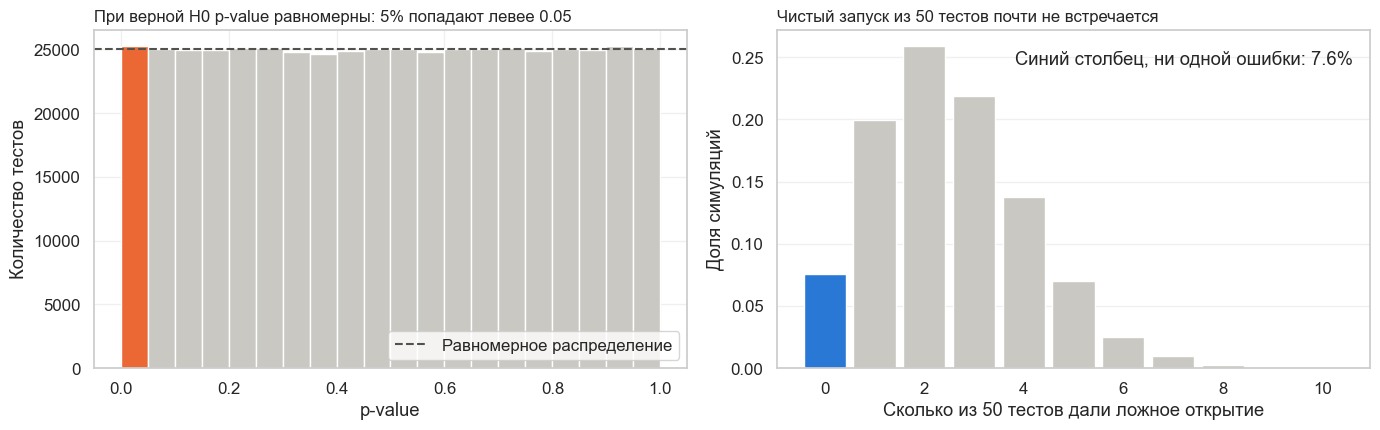

In [3]:
rng = np.random.default_rng(42)  # Для воспроизводимости результатов

# Параметры симуляции
num_hypotheses = 50       # Количество параллельных гипотез (фич)
alpha_level = 0.05        # Уровень значимости для каждого отдельного теста
num_simulations = 10_000  # Количество итераций симуляции для эмпирической оценки
group_size = 200          # Размер каждой группы (контрольной и тестовой)
mu = 0                    # Среднее значение для генерации данных (нет эффекта)
std = 1                   # Стандартное отклонение для генерации данных

all_pvalues = np.zeros((num_simulations, num_hypotheses))

for sim in tqdm(range(num_simulations)):
    # Каждая строка матрицы — один независимый A/A-тест
    control_group = rng.normal(mu, std, size=(num_hypotheses, group_size))
    treatment_group = rng.normal(mu, std, size=(num_hypotheses, group_size))
    all_pvalues[sim] = stats.ttest_ind(control_group, treatment_group, axis=1).pvalue

# В A/A-тесте все эффекты нулевые, поэтому каждое отклонение ложное: V = R
false_positives_V = np.sum(all_pvalues <= alpha_level, axis=1)
total_rejections_R = false_positives_V

# Эмпирическая оценка FWER: доля симуляций хотя бы с одним ложным открытием
empirical_fwer = np.mean(false_positives_V >= 1)
# Эмпирическая оценка FDR: среднее V/R, где при R = 0 доля считается равной 0
empirical_fdr = np.mean(false_positives_V / np.maximum(total_rejections_R, 1))

print(f"Эмпирический FWER для {num_hypotheses} гипотез при alpha={alpha_level}: {empirical_fwer:.4f}")
print(f"Эмпирический FDR для {num_hypotheses} гипотез при alpha={alpha_level}: {empirical_fdr:.4f}")
print(f"Теоретическое значение 1 - (1 - alpha)^m: {1 - (1 - alpha_level) ** num_hypotheses:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

bins = np.linspace(0, 1, 21)
heights, _, patches = axes[0].hist(all_pvalues.ravel(), bins=bins, color='#c9c8c2', edgecolor='white')
patches[0].set_facecolor(NULL_COLOR)
axes[0].axhline(heights.mean(), color=REFERENCE_COLOR, linestyle='--', linewidth=1.5, label='Равномерное распределение')
axes[0].set_title('При верной H0 p-value равномерны: 5% попадают левее 0.05', loc='left', fontsize=12)
axes[0].set_xlabel('p-value')
axes[0].set_ylabel('Количество тестов')
axes[0].legend(loc='lower right')

values, frequencies = np.unique(false_positives_V, return_counts=True)
axes[1].bar(values, frequencies / num_simulations, color='#c9c8c2', width=0.85)
axes[1].patches[0].set_facecolor(REAL_COLOR)
axes[1].text(0.97, 0.9, f'Синий столбец, ни одной ошибки: {frequencies[0] / num_simulations:.1%}', transform=axes[1].transAxes, ha='right')
axes[1].set_title('Чистый запуск из 50 тестов почти не встречается', loc='left', fontsize=12)
axes[1].set_xlabel('Сколько из 50 тестов дали ложное открытие')
axes[1].set_ylabel('Доля симуляций')
axes[1].grid(axis='x', visible=False)

plt.tight_layout()
plt.show()

## Формальное обоснование

Предположим, у нас есть $m$ проверяемых нулевых гипотез: $H_1, H_2, \ldots, H_m$. Результаты этих тестов можно классифицировать следующим образом:

|                   | Нулевая гипотеза верна ($H_0$) | Альтернативная гипотеза верна ($H_A$) | Всего                  |
| :---------------- | :----------------------------- | :---------------------------------- | :--------------------- |
| **Отклоняем $H_0$** | $V$ (ложноположительные)         | $S$ (истинноположительные)        | $R = V + S$ (все отклонённые) |
| **Не отклоняем $H_0$** | $U$ (истинноотрицательные)     | $T$ (ложноотрицательные)          | $m - R$                |
| **Всего**         | $m_0$ (истинные $H_0$)           | $m - m_0$ (истинные $H_A$)          | $m$ (общее число гипотез) |

Здесь:
*   $m$: общее количество тестируемых гипотез.
*   $m_0$: неизвестное количество истинных нулевых гипотез.
*   $V$: количество **ложноположительных результатов (ошибок первого рода)**, также называемых «ложными открытиями».
*   $S$: количество **истинноположительных результатов**, или «истинных открытий».
*   $R = V + S$: общее количество **отклонённых нулевых гипотез**, или «открытий».
*   $T$: количество **ложноотрицательных результатов (ошибок второго рода)**.
*   $U$: количество **истинноотрицательных результатов**.

**FWER (Family-Wise Error Rate)**

**FWER** — это вероятность того, что **хотя бы одна** из истинных нулевых гипотез будет ошибочно отклонена. Формально:
$$ \text{FWER} = P(V \geq 1) $$

Это самый строгий из распространённых критериев: он ограничивает шанс на любую ошибку первого рода во всём семействе тестов.

Предположим, что все $m$ нулевых гипотез истинны ($m_0 = m$), а тесты статистически **независимы**. Вероятность не совершить ошибку первого рода в одном тесте равна $1 - \alpha$, поэтому вероятность не совершить ни одной такой ошибки равна произведению:
$$ P(V=0) = (1-\alpha)^m $$
Следовательно, вероятность совершить хотя бы одну ошибку первого рода равна:
$$ \text{FWER} = 1 - P(V=0) = \mathbf{1 - (1-\alpha)^m} $$

Когда произведение $m\alpha$ мало, работает линейное приближение:
$$ 1 - (1-\alpha)^m \approx m\alpha $$
Для любых $m$ величина $m\alpha$ остаётся верхней границей для FWER, но при большом числе тестов эта граница бесполезна: при $m = 50$ и $\alpha = 0.05$ она равна 2.5, а реальный FWER составляет около 0.92.

Различают два вида контроля. **Слабый контроль** гарантирует $\text{FWER} \le \alpha$ только тогда, когда верны все нулевые гипотезы. **Сильный контроль** гарантирует это при любом наборе истинных и ложных гипотез. На практике нужен именно сильный контроль, потому что мы не знаем, какие гипотезы верны. Все FWER-поправки из этой лекции дают сильный контроль.

**FDR (False Discovery Rate)**

**FDR** — это ожидаемая доля ложных открытий среди всех сделанных открытий. Формально:
$$ \text{FDR} = E\left[\frac{V}{R}\right] $$
Если $R=0$, доля $V/R$ по определению равна 0. Поэтому более точная запись:
$$ \text{FDR} = E\left[\frac{V}{\max(R,1)}\right] $$
FWER ограничивает вероятность хотя бы одного ложного открытия, а FDR ограничивает их среднюю *долю*. Поскольку $V / \max(R, 1) \le \mathbb{1}\{V \ge 1\}$, всегда выполняется $\text{FDR} \le \text{FWER}$. Поэтому FDR менее строгий, но более мощный подход. Его часто используют в разведочных исследованиях, где допустима некоторая доля ложных открытий, если истинных открытий заметно больше.

Когда **все $m$ нулевых гипотез истинны** ($m_0 = m$), любое отклонение ложно и $V = R$. Тогда
$$ \frac{V}{\max(R,1)} = \begin{cases} 1 & \text{если } R > 0 \\ 0 & \text{если } R = 0 \end{cases} $$
и математическое ожидание этой величины равно вероятности хотя бы одного отклонения:
$$ \text{FDR} = 1 \cdot P(R > 0) + 0 \cdot P(R = 0) = P(V \geq 1) = \text{FWER} $$
Это равенство не требует независимости. Если же тесты ещё и независимы, то:
$$ \mathbf{\text{FDR} = \text{FWER} = 1 - (1-\alpha)^m} $$

Как только появляются реальные эффекты, метрики расходятся: истинные открытия увеличивают знаменатель $R$ и снижают FDR, а на FWER они не влияют.

Посмотрим на это на графиках. Чтобы считать быстро, сразу сгенерируем z-статистики: у гипотез без эффекта $z \sim N(0, 1)$, а реальный эффект сдвигает $z$ на величину `effect`. Сдвиг 2.8 соответствует мощности 80% при $\alpha = 0.05$.

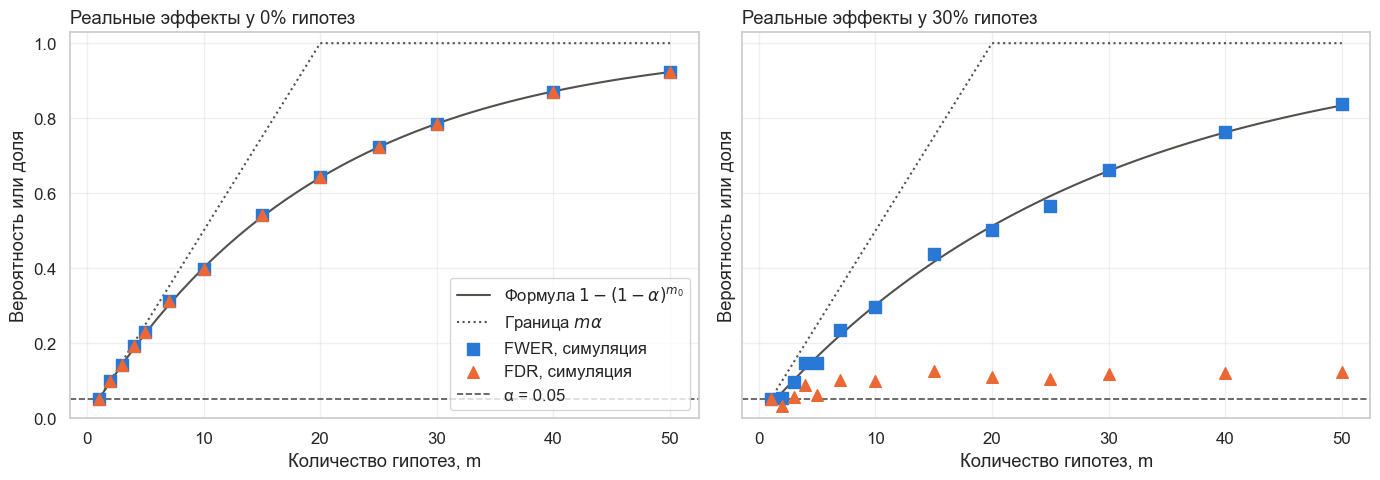

In [4]:
def simulate_pvalues(n_sims: int, m: int, n_real: int, effect: float, rng: np.random.Generator) -> np.ndarray:
    """Генерирует p-value двусторонних z-тестов: у первых n_real гипотез есть эффект, у остальных нет."""
    z = rng.standard_normal((n_sims, m))
    z[:, :n_real] += effect
    return 2 * stats.norm.sf(np.abs(z))


def error_rates(rejected: np.ndarray, n_real: int) -> dict:
    """Считает FWER, FDR и среднюю мощность по матрице решений (симуляции x гипотезы)."""
    V = rejected[:, n_real:].sum(axis=1)
    S = rejected[:, :n_real].sum(axis=1)
    R = V + S
    return {
        'FWER': np.mean(V >= 1),
        'FDR': np.mean(V / np.maximum(R, 1)),
        'Мощность': S.mean() / n_real if n_real > 0 else np.nan,
    }


def plot_fwer_fdr(ax, alpha: float = 0.05, share_real: float = 0.0, effect: float = 2.8, n_sims: int = 4000) -> None:
    """Рисует FWER и FDR без поправок в зависимости от числа гипотез m."""
    rng = np.random.default_rng(42)
    m_grid = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30, 40, 50])
    n_real_grid = np.round(share_real * m_grid).astype(int)

    rates = [error_rates(simulate_pvalues(n_sims, m, n_real, effect, rng) <= alpha, n_real)
             for m, n_real in zip(m_grid, n_real_grid)]

    fine_grid = np.arange(1, 51)
    ax.plot(fine_grid, 1 - (1 - alpha) ** (fine_grid * (1 - share_real)), color=REFERENCE_COLOR, linewidth=1.5,
            label='Формула $1 - (1-\\alpha)^{m_0}$')
    ax.plot(fine_grid, np.minimum(fine_grid * alpha, 1), color=REFERENCE_COLOR, linewidth=1.5, linestyle=':',
            label='Граница $m\\alpha$')
    ax.scatter(m_grid, [r['FWER'] for r in rates], s=70, color=REAL_COLOR, marker='s', zorder=3, label='FWER, симуляция')
    ax.scatter(m_grid, [r['FDR'] for r in rates], s=70, color=NULL_COLOR, marker='^', zorder=3, label='FDR, симуляция')
    ax.axhline(alpha, color=REFERENCE_COLOR, linestyle='--', linewidth=1.2, label=f'α = {alpha:.2f}')
    ax.set_ylim(0, 1.03)
    ax.set_xlabel('Количество гипотез, m')
    ax.set_ylabel('Вероятность или доля')
    ax.set_title(f'Реальные эффекты у {share_real:.0%} гипотез', loc='left')


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
plot_fwer_fdr(axes[0], share_real=0.0)
plot_fwer_fdr(axes[1], share_real=0.3)
axes[0].legend(loc='lower right')
plt.tight_layout()
plt.show()

Слева все нулевые гипотезы верны: точки FWER и FDR совпадают и лежат на формуле. Справа 30% гипотез имеют реальный эффект: FWER продолжает расти, а FDR стабилизируется на низком уровне.

**Попробуйте сами.** Эта ячейка интерактивная: запустите её в Colab или Jupyter и подвигайте ползунки. Попробуйте увеличить долю реальных эффектов или уменьшить силу эффекта: при слабых эффектах истинных открытий мало, и FDR снова растёт.

In [5]:
def fwer_fdr_demo(alpha: float = 0.05, share_real: float = 0.3, effect: float = 2.8) -> None:
    fig, ax = plt.subplots(figsize=(10, 5))
    plot_fwer_fdr(ax, alpha, share_real, effect)
    ax.legend(loc='center right')
    plt.tight_layout()
    plt.show()


interact(fwer_fdr_demo,
         alpha=FloatSlider(value=0.05, min=0.01, max=0.2, step=0.01, description='α'),
         share_real=FloatSlider(value=0.3, min=0, max=0.9, step=0.1, description='Доля эффектов'),
         effect=FloatSlider(value=2.8, min=0.5, max=5, step=0.1, description='Сдвиг z'));

## Критические последствия

Некорректный учёт множественного тестирования имеет серьёзные последствия в разных областях:

*   **Медицина: почему здесь важен FWER.** Здесь безопасность пациентов важнее всего. Если при сравнении нескольких доз, групп пациентов или конечных точек мы проверим много гипотез без поправки, случайный «положительный» эффект может выглядеть как доказанная эффективность. **Одного такого ложного открытия** достаточно, чтобы неэффективный препарат был одобрен и назначался вместо рабочего лечения. Поэтому регуляторы обычно требуют строгого контроля FWER по ключевым гипотезам.

*   **E-commerce: почему здесь часто берут FDR.** В электронной коммерции и рекомендациях число гипотез (дизайны кнопок, варианты рекомендаций, рекламные креативы) может достигать сотен и тысяч. Строгий контроль FWER здесь часто оказывается слишком консервативным и приводит к потере мощности, поэтому контролируют **FDR**. Если же не контролировать ничего, получаются **десятки или сотни ложноположительных «побед»**. Например, команда внедряет «новый алгоритм рекомендаций», который на самом деле не приносит пользы. Это приводит к **неэффективному расходованию ресурсов**, замедлению роста продукта и потере доверия к data-driven подходу.

*   **P-hacking и невоспроизводимость исследований.** Практика перебирать сравнения, метрики и срезы, пока не найдётся что-то «значимое», называется **p-hacking**. Она порождает **ложные корреляции** (spurious correlations), которые появляются просто из-за огромного числа возможных сравнений. Масштабный проект **Open Science Collaboration (2015)** пытался воспроизвести 100 психологических исследований, и статистически значимый результат удалось получить лишь примерно в 36% повторений. Множественные сравнения считаются одной из причин такого разрыва наряду с низкой мощностью исходных исследований и тем, что публикуются в основном значимые результаты.

Для решения проблемы разработаны разные корректирующие процедуры: поправка Бонферрони, метод Холма, метод Бенджамини–Хохберга, метод Бенджамини–Йекутиели и другие. Каждая из них имеет свои преимущества и ограничения в зависимости от требуемого уровня контроля ошибок и структуры зависимостей в данных.

## Методы контроля ошибок

### FWER

#### Поправка Бонферрони

**Формулировка**

Метод Бонферрони предлагает использовать для проверки каждой гипотезы уровень значимости $\alpha/m$, где $m$ — количество гипотез. Гипотеза отвергается, если её $p$-value удовлетворяет условию $p_i \le \alpha/m$.

**Доказательство**

Поправка гарантирует $\text{FWER} \le \alpha$. Это следует из неравенства Буля: вероятность того, что произойдёт хотя бы одно из конечного набора событий, не больше суммы вероятностей этих событий.

Пусть $I_0$ — множество истинных нулевых гипотез, их $m_0 \le m$ штук. Ложное открытие возможно только среди них, и для каждой такой гипотезы $P(p_i \le \alpha/m) \le \alpha/m$:

$$
\text{FWER} = P(V \ge 1) = P\left\{\bigcup _{i \in I_0}\left(p_{i}\leq {\frac {\alpha }{m}}\right)\right\}\leq \sum _{i \in I_0}P\left(p_{i}\leq {\frac {\alpha }{m}}\right)\leq m_0{\frac {\alpha }{m}}\leq\alpha
$$

Доказательство не использует независимость, поэтому поправка работает при **любой** зависимости между тестами.

**Замечание**

Метод Бонферрони прост в реализации, но консервативен. Его основной минус в том, что с ростом числа гипотез он сильно снижает мощность критерия, то есть увеличивает вероятность ошибки второго рода. Другие поправки уступают ему в простоте, но выигрывают в мощности.

In [6]:
def apply_bonferroni_correction(pvalues: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Ручная реализация поправки Бонферрони."""
    return pvalues <= alpha / len(pvalues)

#### Метод Холма (поправка Холма — Бонферрони)

**Алгоритм**

1. Упорядочить $p$-value по возрастанию: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$.
2. Последовательно проверять их, начиная с самого маленького:
   * Если $p_{(1)} \le \alpha/m$, отвергнуть $H_{(1)}$ и перейти к следующему значению. Иначе остановиться и не отвергать ни одну гипотезу.
   * Если $p_{(2)} \le \alpha/(m-1)$, отвергнуть $H_{(2)}$ и перейти к следующему значению. Иначе остановиться.
   * И так далее: на шаге $i$ порог равен $\alpha/(m-i+1)$.
3. На первом шаге $i$, где условие нарушено, остановиться: гипотезы $H_{(i)}, \dots, H_{(m)}$ не отвергаются.

Логика такая: если самую сильную гипотезу мы отвергли, осталось $m-1$ гипотеза, и поправка для них может быть чуть мягче.

**Замечание**

Процедура Холма обеспечивает $\text{FWER} \le \alpha$ при любой зависимости между тестами. Она **равномерно мощнее** метода Бонферрони: отвергает всё то же, что и Бонферрони, и иногда больше. Поэтому Бонферрони для принятия решений всегда можно заменить Холмом.

Более того, без дополнительных предположений о зависимости пороги Холма нельзя поднять, не потеряв гарантию $\text{FWER} \le \alpha$. Более мощные процедуры используют дополнительную информацию, например независимость тестов или логические связи между гипотезами.

In [7]:
def apply_holm_correction(pvalues: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Ручная реализация поправки Холма — Бонферрони."""
    n = len(pvalues)
    sorted_indices = np.argsort(pvalues)
    sorted_pvalues = pvalues[sorted_indices]

    rejected = np.zeros(n, dtype=bool)
    for i, (p, idx) in enumerate(zip(sorted_pvalues, sorted_indices)):
        if p <= alpha / (n - i):
            rejected[idx] = True
        else:
            break  # процедура останавливается на первой неотвергнутой гипотезе

    return rejected

#### Метод Шидака

**Формулировка**

Уровень значимости для $m$ гипотез задаётся так: $\alpha_m = 1 - (1-\alpha)^{1/m}$. Гипотеза отвергается, если $p_i \le \alpha_m$.

**Обоснование**

Если тесты независимы, вероятность отсутствия ошибок первого рода во всех $m$ тестах составляет $(1-\alpha^*)^m$, где $\alpha^*$ — уровень значимости одного теста. Чтобы получить $\text{FWER} = \alpha$, нужно решить $1 - (1-\alpha^*)^m = \alpha$, откуда $\alpha^* = 1 - (1-\alpha)^{1/m}$.

Метод гарантирует $\text{FWER} \le \alpha$ при независимости и при некоторых видах положительной зависимости. В частности, неравенство Шидака выполняется для двусторонних z-тестов с совместно нормальными статистиками при любых корреляциях. При произвольной зависимости гарантии нет.

**Замечание**

Выигрыш по сравнению с Бонферрони почти незаметен: при $m = 10$ и $\alpha = 0.05$ порог Шидака равен 0.00512, а порог Бонферрони равен 0.005. Поэтому на практике Шидака используют редко. Если независимость выполнена, можно применить пошаговый вариант **Холма–Шидака**: в `statsmodels` это `method='holm-sidak'`.

In [8]:
def apply_sidak_correction(pvalues: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Ручная реализация поправки Шидака."""
    n = len(pvalues)
    sidak_alpha = 1 - (1 - alpha) ** (1 / n)
    return pvalues <= sidak_alpha

### FDR

#### Процедура Бенджамини–Хохберга

**Алгоритм**

1. Упорядочить $p$-value по возрастанию: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$.
2. Найти наибольшее $k$ такое, что $p_{(k)} \le \frac{k}{m}\alpha$.
3. Отклонить нулевые гипотезы $H_{(i)}$ для всех $i = 1, \dots, k$.

Геометрически это выглядит так: строим график $p_{(k)}$ от $k$, проводим через начало координат прямую с наклоном $\alpha/m$ и находим **самую правую** точку, которая не лежит выше прямой. Открытиями объявляем её и все точки слева, даже если некоторые из них лежат выше прямой.

Бенджамини и Хохберг доказали в 1995 году, что для независимых тестов процедура даёт $\text{FDR} \le \frac{m_0}{m}\alpha \le \alpha$. В 2001 году Бенджамини и Йекутиели показали, что этот результат сохраняется и при положительной зависимости особого вида (PRDS).

**Чем это отличается от Холма**

Холм идёт от маленьких p-value к большим и останавливается на первой неудаче, а BH идёт с другого конца и останавливается на первом успехе. Анимация показывает это на одних и тех же 12 p-value при $\alpha = 0.05$: чёрная линия показывает порог, а кольцо показывает текущую проверку.

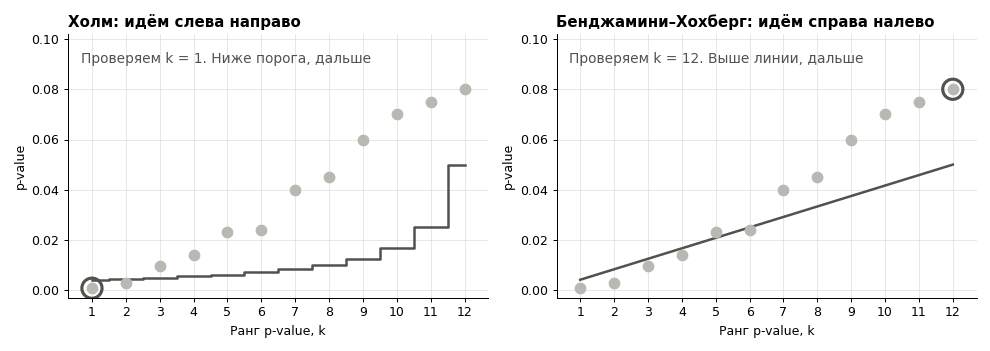

In [9]:
def apply_bh_correction(pvalues: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Ручная реализация метода Бенджамини–Хохберга (FDR)."""
    n = len(pvalues)
    sorted_indices = np.argsort(pvalues)
    sorted_pvalues = pvalues[sorted_indices]

    # Вычисляем критические значения
    critical_values = (np.arange(n) + 1) * alpha / n

    # Находим наибольшее значимое p-value
    max_significant_idx = np.where(sorted_pvalues <= critical_values)[0]
    rejected = np.zeros(n, dtype=bool)
    if len(max_significant_idx) > 0:
        rejected[sorted_indices[:max_significant_idx[-1] + 1]] = True

    return rejected

Теперь сравним пороги на реалистичном примере: 50 гипотез, из них 10 с реальным эффектом. Чтобы разглядеть пороги, ось p-value обрезана сверху.

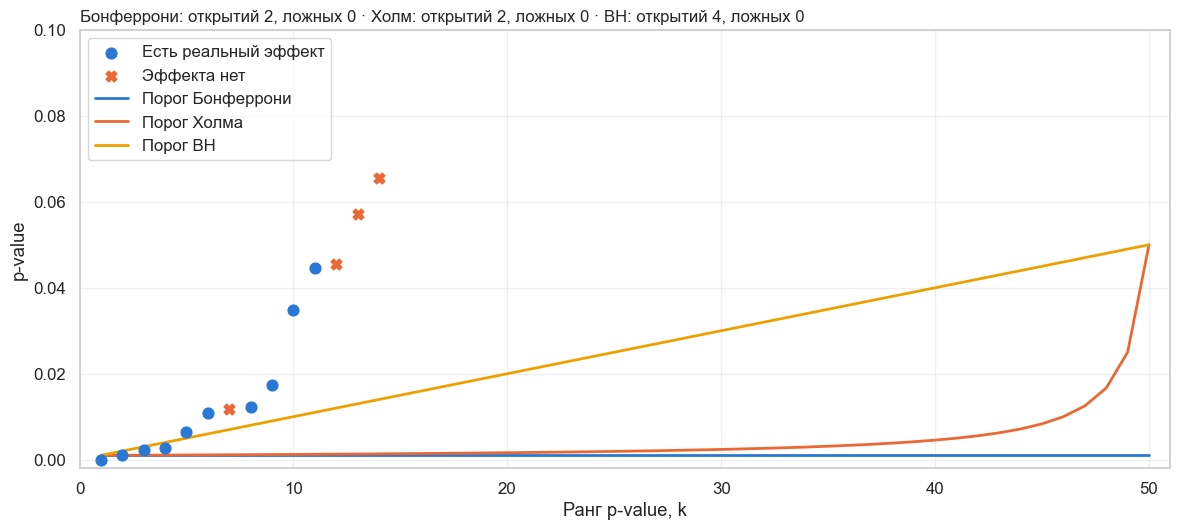

In [10]:
def plot_thresholds(m: int = 50, share_real: float = 0.2, effect: float = 3.0, alpha: float = 0.05, seed: int = 7) -> None:
    """Показывает отсортированные p-value и пороги Бонферрони, Холма и BH."""
    rng = np.random.default_rng(seed)
    n_real = int(round(share_real * m))
    pvalues = simulate_pvalues(1, m, n_real, effect, rng)[0]
    is_real = np.arange(m) < n_real

    order = np.argsort(pvalues)
    ranks = np.arange(1, m + 1)

    fig, ax = plt.subplots(figsize=(12, 5.5))
    ax.scatter(ranks[is_real[order]], pvalues[order][is_real[order]], s=60, color=REAL_COLOR, marker='o',
               zorder=3, label='Есть реальный эффект')
    ax.scatter(ranks[~is_real[order]], pvalues[order][~is_real[order]], s=60, color=NULL_COLOR, marker='X',
               zorder=3, label='Эффекта нет')
    ax.plot(ranks, np.full(m, alpha / m), color=METHOD_STYLE['Бонферрони'][0], linewidth=2, label='Порог Бонферрони')
    ax.plot(ranks, alpha / (m - ranks + 1), color=METHOD_STYLE['Холм'][0], linewidth=2, label='Порог Холма')
    ax.plot(ranks, ranks * alpha / m, color=METHOD_STYLE['BH'][0], linewidth=2, label='Порог BH')

    summary = []
    for name, correction in [('Бонферрони', apply_bonferroni_correction), ('Холм', apply_holm_correction),
                             ('BH', apply_bh_correction)]:
        rejected = correction(pvalues, alpha)
        summary.append(f'{name}: открытий {rejected.sum()}, ложных {(rejected & ~is_real).sum()}')

    ax.set_ylim(-0.02 * alpha * 2, alpha * 2)
    ax.set_xlim(0, m + 1)
    ax.set_title(' · '.join(summary), loc='left', fontsize=12)
    ax.set_xlabel('Ранг p-value, k')
    ax.set_ylabel('p-value')
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


plot_thresholds()

**Попробуйте сами.** Ползунки меняют число гипотез, долю реальных эффектов и их силу. Значение `seed` генерирует новый набор данных. Обратите внимание, что порог BH растёт с $k$: чем больше сильных сигналов, тем мягче он становится. Пороги Бонферрони и Холма такого преимущества почти не получают.

In [11]:
interact(plot_thresholds,
         m=IntSlider(value=50, min=10, max=200, step=10, description='m'),
         share_real=FloatSlider(value=0.2, min=0, max=0.8, step=0.05, description='Доля эффектов'),
         effect=FloatSlider(value=3.0, min=1, max=5, step=0.25, description='Сдвиг z'),
         alpha=FloatSlider(value=0.05, min=0.01, max=0.2, step=0.01, description='α'),
         seed=IntSlider(value=7, min=1, max=50, description='seed'));

#### Метод Бенджамини–Йекутиели (BY)

**Формулировка**

Процедура Бенджамини–Йекутиели (Benjamini–Yekutieli, BY) контролирует FDR при **произвольной** зависимости между тестовыми статистиками. Она работает как BH, но с более строгим порогом: ищем наибольшее $k$ такое, что $p_{(k)} \le \frac{k}{m \cdot c(m)}\alpha$, где

$$ c(m) = \sum_{i=1}^{m} \frac{1}{i} \approx \ln(m) + \gamma + \frac{1}{2m}, \quad \gamma \approx 0.5772 $$

Здесь $c(m)$ — гармоническое число, а $\gamma$ — постоянная Эйлера–Маскерони. Если подставить $c(m) = 1$, получится обычная процедура BH.

BY универсальнее BH, потому что не требует независимости или положительной зависимости. Плата за это — потеря мощности: при $m = 50$ все пороги строже порогов BH примерно в 4.5 раза.

In [12]:
def apply_by_correction(pvalues: np.ndarray, alpha: float = 0.05) -> np.ndarray:
    """Ручная реализация метода Бенджамини–Йекутиели (BY)."""
    n = len(pvalues)
    c_n = np.sum(1 / np.arange(1, n + 1))  # Гармоническое число

    sorted_indices = np.argsort(pvalues)
    sorted_pvalues = pvalues[sorted_indices]

    # Вычисляем критические значения BY
    critical_values = (np.arange(n) + 1) * alpha / (n * c_n)

    # Находим наибольшее значимое p-value
    max_significant_idx = np.where(sorted_pvalues <= critical_values)[0]
    rejected = np.zeros(n, dtype=bool)
    if len(max_significant_idx) > 0:
        rejected[sorted_indices[:max_significant_idx[-1] + 1]] = True

    return rejected

### Проверка ручных реализаций

Сверим наши функции с библиотекой `statsmodels` на случайных наборах p-value. Выбор с возвращением нужен, чтобы в наборы попадали одинаковые значения: на них реализации чаще всего расходятся.

In [13]:
CORRECTIONS = {
    'Бонферрони': apply_bonferroni_correction,
    'Холм': apply_holm_correction,
    'Шидак': apply_sidak_correction,
    'BH': apply_bh_correction,
    'BY': apply_by_correction,
}
STATSMODELS_NAMES = {'Бонферрони': 'bonferroni', 'Холм': 'holm', 'Шидак': 'sidak', 'BH': 'fdr_bh', 'BY': 'fdr_by'}

rng = np.random.default_rng(42)
for name, correction in CORRECTIONS.items():
    for _ in range(300):
        pvalues = rng.choice(rng.beta(0.3, 2, size=20), size=rng.integers(2, 40), replace=True)
        alpha = rng.choice([0.01, 0.05, 0.1])
        assert np.array_equal(correction(pvalues, alpha), multipletests(pvalues, alpha, STATSMODELS_NAMES[name])[0]), name

print('Все ручные реализации совпали со statsmodels')

Все ручные реализации совпали со statsmodels


### Скорректированные p-value

На практике вместо изменения порога часто корректируют сами p-value. Скорректированное p-value сравнивается с исходным $\alpha$: гипотеза отвергается, если оно не больше $\alpha$. Такой подход удобнее для отчётов, потому что решение можно принять сразу для любого $\alpha$. Функция `multipletests` возвращает эти значения вторым элементом результата.

In [14]:
example_pvalues = np.array([0.001, 0.008, 0.012, 0.041, 0.074, 0.28])

adjusted = pd.DataFrame({'Исходное p-value': example_pvalues})
for name in ['Бонферрони', 'Холм', 'BH', 'BY']:
    adjusted[name] = multipletests(example_pvalues, method=STATSMODELS_NAMES[name])[1]

adjusted.round(3)

,Исходное p-value,Бонферрони,Холм,BH,BY
0,0.001,0.006,0.006,0.006,0.015
1,0.008,0.048,0.040,0.024,0.059
2,0.012,0.072,0.048,0.024,0.059
3,0.041,0.246,0.123,0.062,0.151
4,0.074,0.444,0.148,0.089,0.218
5,0.280,1.000,0.280,0.280,0.686


### Что в итоге использовать?

Для начала разберёмся с метрикой: как выбрать между FWER и FDR? Единственного правильного ответа нет, всё зависит от конкретного кейса.

* Если гипотез много и **хочется выбрать наиболее интересные** для дальнейшего анализа, можно опираться на **FDR**: так мы пропустим меньше реальных эффектов, а отдельная ложная находка обойдётся недорого.

* Если гипотез немного и фича **может сильно повлиять на ключевые метрики** (например, на деньги), особенно в отрицательную сторону, надёжнее использовать **FWER**, потому что он строже ограничивает ошибки первого рода.

Перед выбором поправки нужно определить **семейство гипотез**, то есть набор проверок, внутри которого мы считаем ошибки. Обычно это сравнения одного эксперимента, по которым принимается одно решение. Семейство фиксируется до запуска, иначе его можно незаметно подогнать под нужный результат.

Выбор метода можно сформулировать строже:

| Метод | Контролирует | Требования к зависимости | Когда использовать |
| :--- | :--- | :--- | :--- |
| Бонферрони | FWER | Нет | Для расчёта размера выборки и быстрой оценки при небольшом числе сравнений |
| Холм | FWER | Нет | Выбор по умолчанию для FWER |
| Шидак | FWER | Независимость или положительная зависимость | Редко, потому что выигрыш почти незаметен |
| Бенджамини–Хохберг | FDR | Независимость или PRDS | Выбор по умолчанию для FDR |
| Бенджамини–Йекутиели | FDR | Нет | Когда зависимость между тестами может быть отрицательной или неизвестна |

Для типовых схем сравнений есть специальные критерии, которые учитывают зависимость и поэтому мощнее универсальных поправок. Сравнения всех групп с одной контрольной выполняет **тест Даннета** (`scipy.stats.dunnett`), а сравнения всех пар групп выполняет **тест Тьюки** (`scipy.stats.tukey_hsd`).

### Симуляция

Сначала повторим частый сценарий: 5 групп без каких-либо эффектов и попарное сравнение всех со всеми, всего 10 тестов. Эти тесты зависимы, потому что каждая группа участвует сразу в четырёх сравнениях. Здесь FWER совпадает с FDR, потому что все нулевые гипотезы верны.

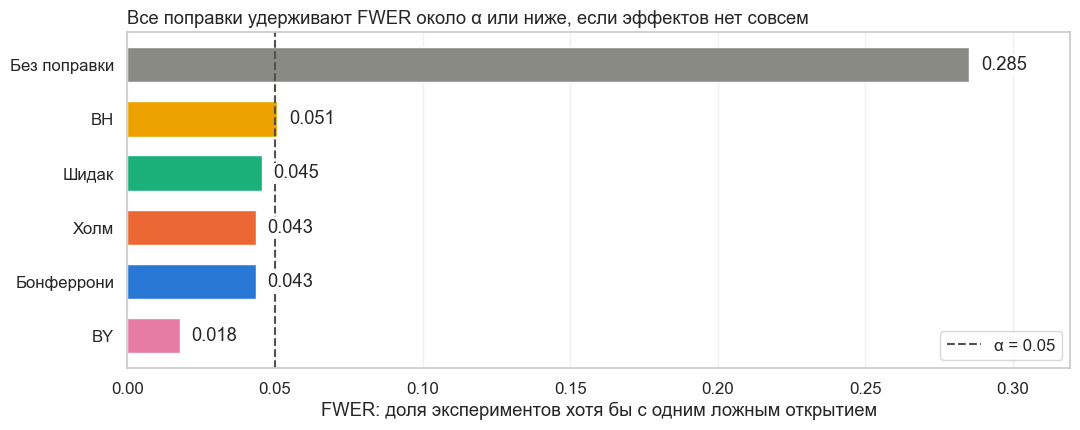

Формула для независимых тестов дала бы 0.401, симуляция без поправки: 0.285


In [15]:
def pairwise_pvalues(data: np.ndarray) -> np.ndarray:
    """Выполняет попарные t-тесты Уэлча между строками матрицы data."""
    return np.array([stats.ttest_ind(a, b, equal_var=False).pvalue for a, b in itertools.combinations(data, 2)])


def simulate_pairwise_fwer(n_runs: int, n_groups: int, n_per_group: int, alpha: float, seed: int) -> pd.Series:
    """Оценивает FWER при попарных сравнениях групп без эффекта."""
    rng = np.random.default_rng(seed)
    any_rejected = {name: 0 for name in ['Без поправки', *CORRECTIONS]}

    for _ in tqdm(range(n_runs), desc="Симуляция экспериментов"):
        pvalues = pairwise_pvalues(rng.normal(size=(n_groups, n_per_group)))
        any_rejected['Без поправки'] += np.any(pvalues <= alpha)
        for name, correction in CORRECTIONS.items():
            any_rejected[name] += np.any(correction(pvalues, alpha))

    return pd.Series(any_rejected) / n_runs


pairwise_fwer = simulate_pairwise_fwer(n_runs=4000, n_groups=5, n_per_group=100, alpha=0.05, seed=42)

fig, ax = plt.subplots(figsize=(11, 4.5))
ordered = pairwise_fwer.sort_values()
ax.barh(ordered.index, ordered.values, color=[METHOD_STYLE[name][0] for name in ordered.index], height=0.65)
for position, value in enumerate(ordered.values):
    ax.text(value + 0.004, position, f'{value:.3f}', va='center', bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
ax.axvline(0.05, color=REFERENCE_COLOR, linestyle='--', linewidth=1.5, label='α = 0.05')
ax.set_xlim(0, ordered.max() * 1.12)
ax.set_title('Все поправки удерживают FWER около α или ниже, если эффектов нет совсем', loc='left')
ax.set_xlabel('FWER: доля экспериментов хотя бы с одним ложным открытием')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f"Формула для независимых тестов дала бы {1 - 0.95 ** 10:.3f}, симуляция без поправки: {pairwise_fwer['Без поправки']:.3f}")

FWER без поправки здесь ниже, чем даёт формула для независимых тестов: положительная зависимость делает ложные срабатывания «кучнее».

Но сценарий без единого эффекта не показывает разницу между методами: здесь FDR совпадает с FWER, поэтому BH выглядит как метод контроля FWER. Настоящая разница видна, когда часть эффектов реальна. Возьмём 20 независимых гипотез и будем менять долю реальных эффектов.

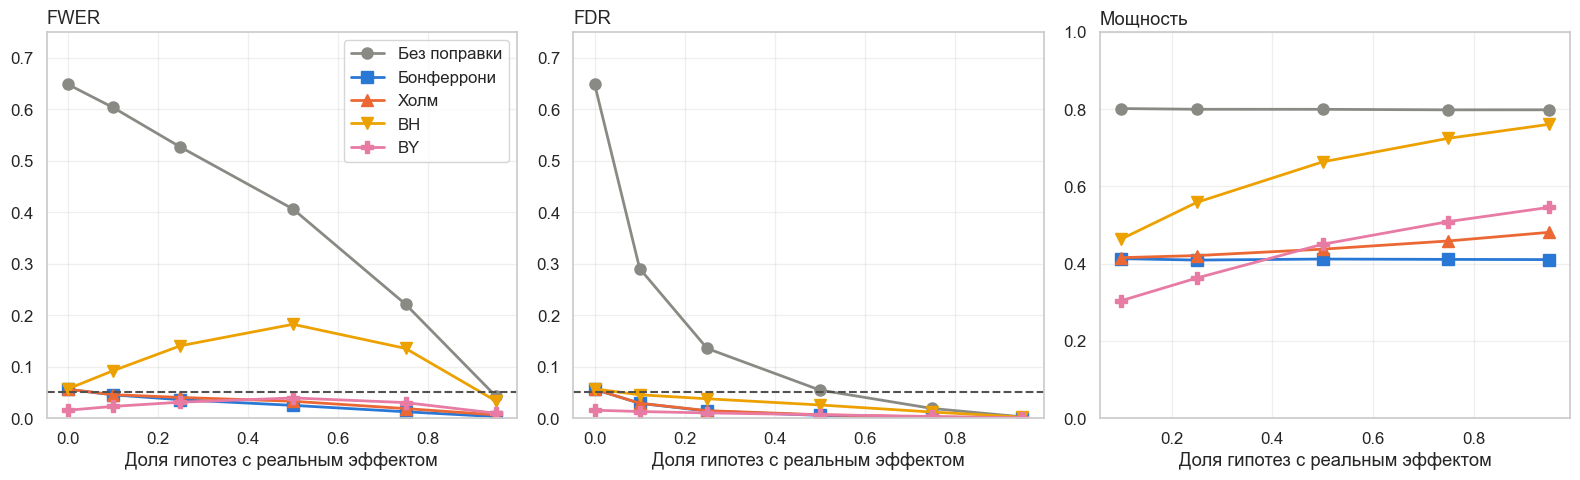

,FWER,FDR,Мощность
Метод,,,
Без поправки,0.526,0.135,0.800
Бонферрони,0.036,0.014,0.409
Холм,0.040,0.015,0.421
BH,0.141,0.038,0.559
BY,0.031,0.010,0.363


In [16]:
def compare_methods(m: int = 20, effect: float = 2.8, alpha: float = 0.05, n_sims: int = 5000, seed: int = 42) -> pd.DataFrame:
    """Считает FWER, FDR и мощность методов при разной доле реальных эффектов."""
    rng = np.random.default_rng(seed)
    rows = []
    for n_real in [0, 2, 5, 10, 15, 19]:
        pvalues = simulate_pvalues(n_sims, m, n_real, effect, rng)
        rows.append({'Метод': 'Без поправки', 'Доля эффектов': n_real / m, **error_rates(pvalues <= alpha, n_real)})
        for name in ['Бонферрони', 'Холм', 'BH', 'BY']:
            rejected = np.apply_along_axis(CORRECTIONS[name], 1, pvalues, alpha)
            rows.append({'Метод': name, 'Доля эффектов': n_real / m, **error_rates(rejected, n_real)})
    return pd.DataFrame(rows)


comparison = compare_methods()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, ['FWER', 'FDR', 'Мощность']):
    for name, part in comparison.groupby('Метод', sort=False):
        color, marker = METHOD_STYLE[name]
        ax.plot(part['Доля эффектов'], part[metric], color=color, marker=marker, markersize=8, linewidth=2, label=name)
    if metric != 'Мощность':
        ax.axhline(0.05, color=REFERENCE_COLOR, linestyle='--', linewidth=1.5)
    ax.set_title(metric, loc='left')
    ax.set_xlabel('Доля гипотез с реальным эффектом')
axes[0].legend(loc='upper right')
axes[0].set_ylim(0, 0.75)
axes[1].set_ylim(0, 0.75)
axes[2].set_ylim(0, 1)
plt.tight_layout()
plt.show()

comparison[comparison['Доля эффектов'] == 0.25].set_index('Метод').drop(columns='Доля эффектов').round(3)

Что видно на графиках:

* **FWER.** Бонферрони и Холм держатся ниже $\alpha$ при любой доле эффектов. BH превышает $\alpha$: при 25% эффектов его FWER равен примерно 0.14. Это не дефект, потому что BH обещает контроль другой величины.
* **FDR.** Все поправки удерживают его ниже $\alpha$. У BH при 25% эффектов FDR близок к теоретической границе $\frac{m_0}{m}\alpha = 0.0375$.
* **Мощность.** При 25% эффектов BH находит 56% реальных эффектов, Холм находит 42%, а Бонферрони 41%. Чем больше реальных эффектов, тем сильнее выигрыш BH. Холм мощнее Бонферрони, но заметно это только при большой доле эффектов.
* **Без поправки** мощность максимальна, но при 25% эффектов каждое седьмое открытие оказывается ложным, а FWER превышает 50%.

## Учёт поправок при дизайне эксперимента

Теперь поговорим о том, как учесть множественное тестирование на этапе дизайна эксперимента.

Обычно при планировании мы проверяем, что выбранный критерий обеспечивает нужные значения ошибок первого и второго рода. Для этого берут исторические данные целевых метрик, многократно делят пользователей на control и treatment с заранее рассчитанным размером выборки, считают p-value выбранным критерием и оценивают ошибку первого рода. Чтобы оценить ошибку второго рода, к treatment-группе добавляют эффект.

В нашем случае мы заранее знаем, сколько будет тестовых групп и, следовательно, сколько гипотез мы проверим. Поэтому шаги такие:

1. Выбрать метод контроля ошибки первого рода: FWER, FDR или другой.
2. По аналогии с обычным экспериментом взять данные по интересующей нас метрике за предыдущий период.
3. Оценить размер выборки, необходимый для детекции заданного эффекта.
4. Разделить пользователей на группы и проверить на симуляции контроль выбранной метрики.
5. При необходимости скорректировать размер выборки с учётом желаемой мощности.

### Сетап эксперимента

Пусть у нас есть метрика с нормальным распределением: $\mu = 10$, $\sigma = 1$, $N = 1\,000\,000$ пользователей. Минимальный эффект, который мы хотим детектировать, равен 0.5%. В эксперименте будет 5 групп (1 контрольная и 4 тестовых), и мы сравниваем каждую группу с каждой.

В симуляции у всех четырёх тестовых групп одинаковый эффект. Значит, из 10 попарных сравнений 4 (контроль против теста) содержат реальный эффект, а 6 (тест против теста) не содержат.

#### Функции

In [17]:
def calculate_sample_size(
    effect_size: float,
    alpha: float = 0.05,
    power: float = 0.8,
    alternative: str = 'two-sided'
) -> int:
    """
    Рассчитывает необходимый размер одной группы для t-теста с равными группами.

    Parameters:
        effect_size (float): ожидаемый размер эффекта (Cohen's d).
        alpha (float): уровень значимости.
        power (float): требуемая мощность.
        alternative (str): 'two-sided' или 'larger'/'smaller' для одностороннего теста.

    Returns:
        int: необходимый размер выборки для каждой группы.
    """
    result = TTestIndPower().solve_power(effect_size=effect_size, power=power, alpha=alpha, alternative=alternative)
    return int(np.ceil(result))


def simulate_design(
    values: np.ndarray,
    effect: float,
    sample_size: int,
    n_groups: int,
    n_iter: int,
    alpha: float,
    rng: np.random.Generator
) -> pd.DataFrame:
    """
    Моделирует эксперимент с попарными сравнениями и оценивает ошибки разных поправок.

    Parameters:
        values (np.ndarray): исторические значения метрики.
        effect (float): множитель, который применяется к метрике в тестовых группах.
        sample_size (int): размер выборки для каждой группы.
        n_groups (int): число групп, первая из них контрольная.
        n_iter (int): количество итераций моделирования.
        alpha (float): уровень значимости.
        rng (np.random.Generator): генератор случайных чисел.

    Returns:
        pd.DataFrame: FWER, средняя ошибка II рода и вероятность хотя бы одного пропуска по каждому методу.
    """
    group_pairs = list(itertools.combinations(range(n_groups), 2))
    has_effect = np.array([first == 0 for first, _ in group_pairs])  # реальный эффект только в сравнениях с контролем

    methods = {'Без поправки': lambda p, a: p <= a, **{name: CORRECTIONS[name] for name in ['Бонферрони', 'Холм', 'BH']}}
    rejected = {name: np.zeros((n_iter, len(group_pairs)), dtype=bool) for name in methods}
    treatment_values = values * effect

    for iteration in tqdm(range(n_iter), desc=f'n = {sample_size}'):
        groups = [rng.choice(values, sample_size, replace=True)]
        groups += [rng.choice(treatment_values, sample_size, replace=True) for _ in range(n_groups - 1)]
        pvalues = np.array([stats.ttest_ind(groups[i], groups[j]).pvalue for i, j in group_pairs])
        for name, correction in methods.items():
            rejected[name][iteration] = correction(pvalues, alpha)

    rows = {}
    for name, decisions in rejected.items():
        rows[name] = {
            'FWER': np.mean(decisions[:, ~has_effect].any(axis=1)),
            'Ошибка II рода': 1 - decisions[:, has_effect].mean(),
            'P(хотя бы один пропуск)': np.mean(~decisions[:, has_effect].all(axis=1)),
        }
    return pd.DataFrame(rows).T

#### Симуляция

In [18]:
mu = 10
std = 1
effect = 1.005
population_size = 1_000_000
n_groups = 5

alpha = 0.05
beta = 0.2

rng = np.random.default_rng(42)
df = pd.DataFrame({"metric": rng.normal(mu, std, population_size)})

effect_size = (effect - 1) * mu / std  # эффект в стандартных отклонениях (Cohen's d)
n_comparisons = len(list(itertools.combinations(range(n_groups), 2)))
n_real_comparisons = n_groups - 1

Рассчитаем минимальный объём выборки, необходимый для детекции заданного эффекта без учёта множественности.

In [19]:
n_base = calculate_sample_size(effect_size, alpha=alpha, power=1 - beta)
print(f"Для равных групп необходимо по {n_base} участников в каждой группе.")

Для равных групп необходимо по 6281 участников в каждой группе.


Получаем, что для детекции эффекта в 0.5% на одну группу необходимо примерно 6.3 тыс. объектов. Посмотрим, что будет с ошибками при таком размере групп.

In [20]:
base_errors = simulate_design(df["metric"].values, effect, n_base, n_groups, n_iter=2000, alpha=alpha, rng=rng)
base_errors.round(3)

,FWER,Ошибка II рода,P(хотя бы один пропуск)
Без поправки,0.208,0.213,0.456
Бонферрони,0.026,0.519,0.822
Холм,0.033,0.497,0.785
BH,0.089,0.387,0.630


FWER здесь считается по шести сравнениям без реального эффекта. Что мы видим:

1. Без поправки FWER вырос примерно до 0.2. Бонферрони и Холм удерживают его ниже 0.05, а значение около 0.03 соответствует границе $\frac{m_0}{m}\alpha$ для 6 истинных нулевых гипотез из 10. BH превышает 0.05, потому что гарантирует только контроль FDR.
2. Поправки ожидаемо снижают мощность. Ошибка II рода вырастает с 0.2 примерно до 0.4 у BH и до 0.5 у методов контроля FWER.

Но при возможности мы можем вернуть ошибку II рода к нужному значению.

Уменьшить ошибку второго рода можно, увеличив размер выборки. Это следует из формулы размера одной группы для сравнения двух средних:

$$
N = \frac{2\sigma^2 \left( \Phi^{-1}_{1 - \alpha/2} + \Phi^{-1}_{1 - \beta} \right)^2}{\text{mde}^2}
$$

Поправка фактически уменьшает $\alpha$, поэтому в формулу можно подставить скорректированный уровень значимости.

[Существуют](https://link.springer.com/article/10.1007/s10732-020-09454-w) следующие подходы к коррекции размера выборки:

1. **Худший случай.** Рассчитываем размер выборки так, чтобы нужную мощность имел тест с самым строгим уровнем значимости. Самый строгий уровень даёт поправка Бонферрони: $\alpha_i = \alpha / m$. Это гарантирует заданную мощность каждого сравнения. Сам анализ всё равно стоит проводить методом Холма: он отвергает не меньше гипотез.

2. **Средняя или медианная мощность.** Метод Холма проверяет гипотезы с разными порогами от $\alpha/m$ до $\alpha$, поэтому можно поддерживать на заданном уровне среднюю или медианную мощность тестов. Для медианной мощности достаточно разделить $\alpha$ на $m / 2$. Для средней мощности считаем размер выборки для каждого порога и усредняем:

$$
N = \frac{1}{m} \sum_{i=1}^{m} N\left[ \alpha / i \right]
$$

где $N[\cdot]$ — функция расчёта размера выборки при фиксированных остальных параметрах.

Иногда нужна более сильная гарантия: **обнаружить все реальные эффекты сразу** с вероятностью не меньше $1 - \beta$. Для этого применим к ошибкам второго рода ту же логику Бонферрони. Если реальных эффектов $k$ и каждое сравнение пропускает эффект с вероятностью не больше $\beta / k$, то по неравенству Буля вероятность хотя бы одного пропуска не больше $\beta$. Значит, в формулу нужно подставить $\alpha / m$ и $\beta / k$.

In [21]:
n_by_threshold = [calculate_sample_size(effect_size, alpha=alpha / i, power=1 - beta) for i in range(1, n_comparisons + 1)]

scenarios = {
    'Без коррекции': n_base,
    'Средняя мощность': int(np.ceil(np.mean(n_by_threshold))),
    'Медианная мощность': calculate_sample_size(effect_size, alpha=alpha / (n_comparisons / 2), power=1 - beta),
    'Худший случай': calculate_sample_size(effect_size, alpha=alpha / n_comparisons, power=1 - beta),
    'Все эффекты сразу': calculate_sample_size(effect_size, alpha=alpha / n_comparisons, power=1 - beta / n_real_comparisons),
}

scenario_table = pd.DataFrame({'Размер группы': scenarios})
scenario_table['Рост к базовому, %'] = ((scenario_table['Размер группы'] / n_base - 1) * 100).round(1)
scenario_table

,Размер группы,"Рост к базовому, %"
Без коррекции,6281,0.0
Средняя мощность,9155,45.8
Медианная мощность,9345,48.8
Худший случай,10653,69.6
Все эффекты сразу,15858,152.5


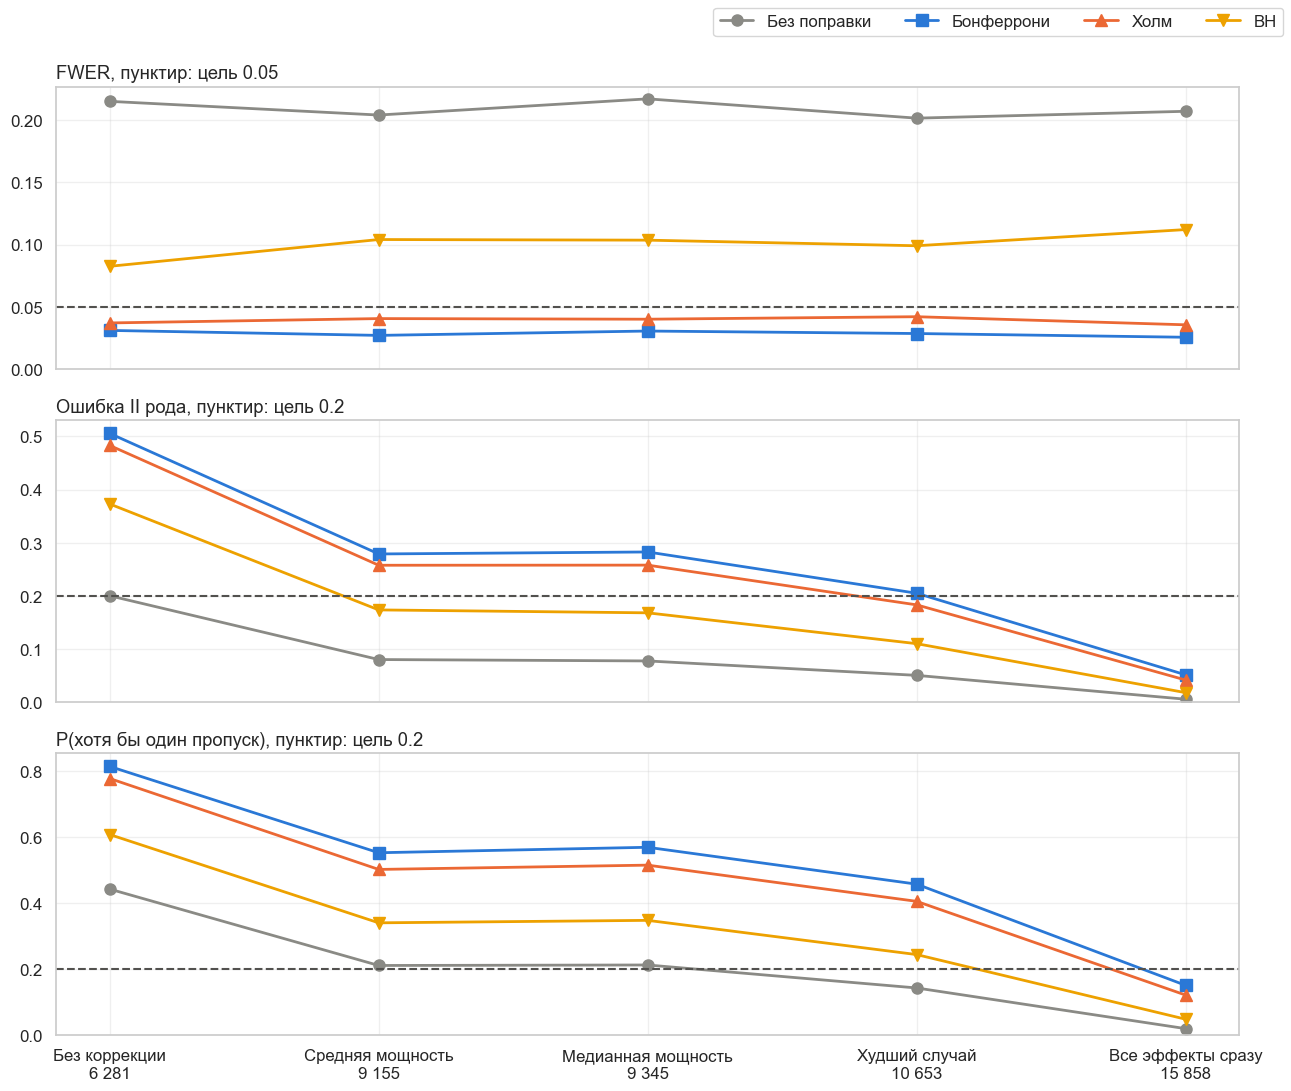

FWER  Ошибка II рода  \
Сценарий           Метод                                 
Без коррекции      Без поправки  0.215           0.200   
                   Бонферрони    0.031           0.506   
                   Холм          0.037           0.483   
                   BH            0.082           0.373   
Средняя мощность   Без поправки  0.204           0.080   
                   Бонферрони    0.027           0.279   
                   Холм          0.040           0.258   
                   BH            0.104           0.174   
Медианная мощность Без поправки  0.217           0.078   
                   Бонферрони    0.030           0.283   
                   Холм          0.040           0.258   
                   BH            0.104           0.168   
Худший случай      Без поправки  0.202           0.050   
                   Бонферрони    0.028           0.205   
                   Холм          0.042           0.183   
                   BH            0.099           0.110   
Все эффекты сразу  Без поправки  0.207           0.006   
                   Бонферрони    0.026           0.051   
                   Холм          0.036           0.042   
                   BH            0.112           0.018   

                                 P(хотя бы один пропуск)  
Сценарий           Метод                                  
Без коррекции      Без поправки                    0.442  
                   Бонферрони                      0.814  
                   Холм                            0.777  
                   BH                              0.608  
Средняя мощность   Без поправки                    0.212  
                   Бонферрони                      0.552  
                   Холм                            0.502  
                   BH                              0.340  
Медианная мощность Без поправки                    0.213  
                   Бонферрони                      0.569  
                   Холм                            0.515  
                   BH                              0.348  
Худший случай      Без поправки                    0.144  
                   Бонферрони                      0.458  
                   Холм                            0.406  
                   BH                              0.244  
Все эффекты сразу  Без поправки                    0.020  
                   Бонферрони                      0.152  
                   Холм                            0.122  
                   BH                              0.049

In [22]:
scenario_errors = {
    name: simulate_design(df["metric"].values, effect, size, n_groups, n_iter=2000, alpha=alpha, rng=rng)
    for name, size in scenarios.items()
}

labels = [f"{name}\n{size:,}".replace(',', ' ') for name, size in scenarios.items()]
targets = {'FWER': alpha, 'Ошибка II рода': beta, 'P(хотя бы один пропуск)': beta}

fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
for ax, (metric, target) in zip(axes, targets.items()):
    for method, (color, marker) in METHOD_STYLE.items():
        if method in base_errors.index:
            values = [scenario_errors[name].loc[method, metric] for name in scenarios]
            ax.plot(labels, values, color=color, marker=marker, markersize=8, linewidth=2, label=method)
    ax.axhline(target, color=REFERENCE_COLOR, linestyle='--', linewidth=1.5)
    ax.set_title(f'{metric}, пунктир: цель {target}', loc='left')
    ax.set_ylim(bottom=0)
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='upper right', ncol=4)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

pd.concat(scenario_errors, names=['Сценарий', 'Метод']).round(3)

Сравним сценарии с целью $\beta = 0.2$:

* **Худший случай** (+70% к размеру группы) даёт ожидаемую ошибку II рода: около 0.2 у Бонферрони и 0.18 у Холма. Именно этот вариант гарантирует заданную мощность методов контроля FWER.
* **Средняя и медианная мощность** (+46–49%) в нашем сетапе не дотягивают: у Холма ошибка II рода равна примерно 0.26. Причина в том, что реальных эффектов только 4 из 10, а их p-value самые маленькие и проверяются на самых строгих порогах от $\alpha/10$ до $\alpha/7$. Эти подходы рассчитаны на случай, когда реальный эффект есть во всех сравнениях. Зато для BH такого размера выборки хватает.
* **Все эффекты сразу** (+153%) гарантирует, что мы обнаружим все 4 эффекта с вероятностью не меньше 80%. Вероятность хотя бы одного пропуска равна примерно 0.15 у Бонферрони и 0.12 у Холма. Она ниже 0.2, потому что неравенство Буля даёт верхнюю границу.

Практический вывод: если нужна гарантия для методов контроля FWER, рассчитывайте выборку по поправке Бонферрони, а анализ проводите методом Холма.

Иногда для обнаружения всех эффектов сразу советуют делить $\alpha$ на $m^2$. Такое правило не имеет обоснования: оно не учитывает число реальных эффектов $k$ и целевую $\beta$. В нашем случае оно дало бы примерно 14.9 тыс. на группу, что близко к результату формулы лишь по совпадению.

#### Распределение трафика по группам

Снизить число пользователей можно и более хитрым распределением по группам.

Пусть есть одна контрольная группа размера $n_c$, $k$ тестовых групп размера $n_t$ и всего $N$ пользователей, то есть $n_c + k n_t = N$. Каждая тестовая группа сравнивается с контрольной t-тестом:

$$
\Large t = \frac{\bar{X}_t - \bar{X}_c}{\sqrt{\frac{s_t^2}{n_t} + \frac{s_c^2}{n_c}}}
$$

При равных дисперсиях дисперсия разности средних пропорциональна $\frac{1}{n_c} + \frac{1}{n_t}$. Она одинакова во всех $k$ сравнениях, поэтому нам нужно минимизировать:

$$\min_{n_c,\, n_t} \left( \frac{1}{n_c} + \frac{1}{n_t} \right) \quad \text{при условии} \quad n_c + k n_t = N$$

Оптимальные размеры групп равны:

$$n_t = \frac{N}{k + \sqrt{k}}, \quad n_c = \frac{N}{1 + \sqrt{k}}$$

Это **правило квадратного корня**: контрольная группа должна быть в $\sqrt{k}$ раз больше каждой тестовой.

**Вывод**

1. Выразим $n_c = N - k n_t$ и получим функцию одной переменной:
$$
f(n_t) = \frac{1}{N - k n_t} + \frac{1}{n_t}
$$

2. Возьмём производную и приравняем её к нулю:
$$
f'(n_t) = \frac{k}{(N - k n_t)^2} - \frac{1}{n_t^2} = 0
$$

$$
\frac{(N - k n_t)^2}{n_t^2} = k
$$

3. Группы имеют положительный размер, поэтому берём положительный корень:
$$
\frac{N - k n_t}{n_t} = \sqrt{k}
$$

$$
N = n_t (k + \sqrt{k})
$$

$$
n_t = \frac{N}{k + \sqrt{k}}
$$

4. Теперь находим размер контрольной группы:
$$
n_c = N - k n_t = N \left( 1 - \frac{k}{k + \sqrt{k}} \right) = N \frac{\sqrt{k}}{k + \sqrt{k}} = \frac{N}{1 + \sqrt{k}}
$$

Итак, окончательное решение:
$$
\boxed{
\begin{aligned}
n_t &= \frac{N}{k + \sqrt{k}}, \\
n_c &= \frac{N}{1 + \sqrt{k}}.
\end{aligned}
}
$$

При $k = 1$ получаем равное деление пополам, как и должно быть. Ниже посчитаем MDE для $k$ сравнений с контролем, применив поправку Бонферрони $\alpha / k$.

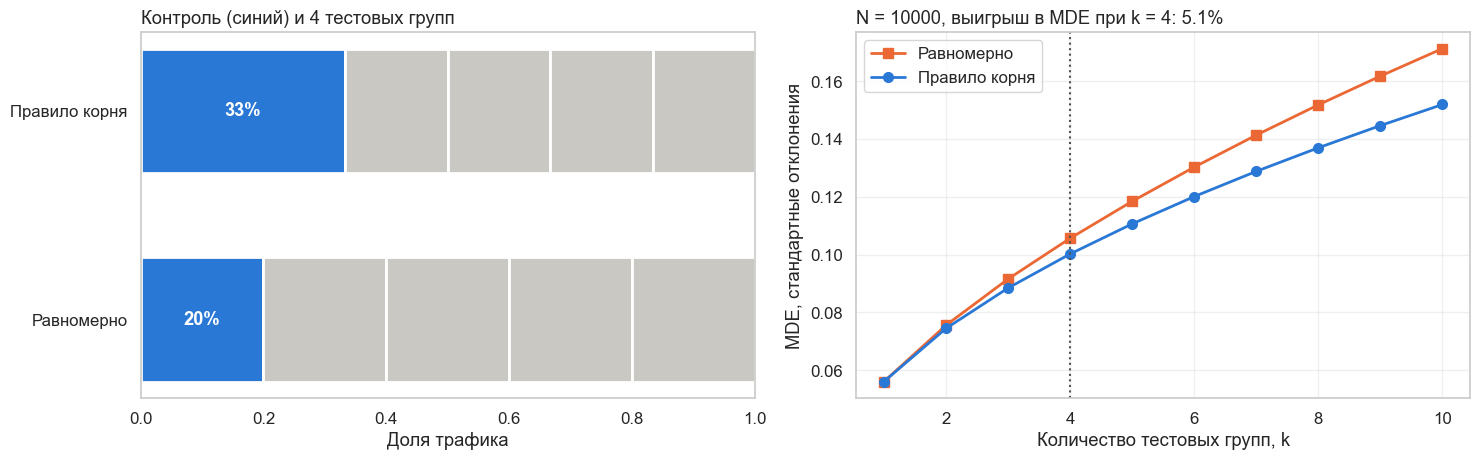

,MDE оптимальное,MDE равномерное,"Улучшение, %"
k,,,
1,0.0560,0.0560,0.0000
2,0.0744,0.0755,1.4412
3,0.0884,0.0915,3.4109
4,0.1002,0.1056,5.1386
5,0.1106,0.1184,6.5938
6,0.1201,0.1303,7.8241
7,0.1288,0.1414,8.8769
8,0.1370,0.1518,9.7891
9,0.1447,0.1618,10.5889


In [23]:
def calculate_mde(n_control: float, n_treatment: float, alpha: float = 0.05, power: float = 0.8) -> float:
    """Вычисляет MDE для t-теста в стандартных отклонениях метрики."""
    df = n_control + n_treatment - 2
    t_alpha = stats.t.ppf(1 - alpha / 2, df)
    t_beta = stats.t.ppf(power, df)
    se = np.sqrt(1 / n_control + 1 / n_treatment)  # метрика стандартизована: дисперсия равна 1
    return (t_alpha + t_beta) * se


def optimal_allocation(N: int, k: int) -> tuple:
    """Вычисляет оптимальные размеры контрольной и одной тестовой группы."""
    return N / (1 + np.sqrt(k)), N / (k + np.sqrt(k))


def uniform_allocation(N: int, k: int) -> tuple:
    """Делит пользователей между группами поровну."""
    return N / (k + 1), N / (k + 1)


def compare_allocations(N: int = 10_000, max_k: int = 10, alpha: float = 0.05, power: float = 0.8) -> pd.DataFrame:
    """Сравнивает MDE при оптимальном и равномерном распределении с поправкой Бонферрони."""
    rows = []
    for k in range(1, max_k + 1):
        mde_optimal = calculate_mde(*optimal_allocation(N, k), alpha / k, power)
        mde_uniform = calculate_mde(*uniform_allocation(N, k), alpha / k, power)
        rows.append({'k': k, 'MDE оптимальное': mde_optimal, 'MDE равномерное': mde_uniform,
                     'Улучшение, %': (mde_uniform - mde_optimal) / mde_uniform * 100})
    return pd.DataFrame(rows).set_index('k')


def allocation_demo(N: int = 10_000, k: int = 4, alpha: float = 0.05, power: float = 0.8) -> None:
    """Показывает разбиение трафика и MDE при оптимальном и равномерном распределении."""
    allocations = compare_allocations(N, 10, alpha, power)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

    for row, (name, allocation) in enumerate([('Равномерно', uniform_allocation), ('Правило корня', optimal_allocation)]):
        n_control, n_treatment = allocation(N, k)
        axes[0].barh(row, n_control / N, color=REAL_COLOR, edgecolor='white', linewidth=2, height=0.6)
        axes[0].text(n_control / N / 2, row, f'{n_control / N:.0%}', ha='center', va='center', color='white', fontweight='bold')
        for group in range(k):
            axes[0].barh(row, n_treatment / N, left=(n_control + group * n_treatment) / N, color='#c9c8c2',
                         edgecolor='white', linewidth=2, height=0.6)
    axes[0].set_yticks([0, 1], ['Равномерно', 'Правило корня'])
    axes[0].set_xlim(0, 1)
    axes[0].set_xlabel('Доля трафика')
    axes[0].set_title(f'Контроль (синий) и {k} тестовых групп', loc='left')
    axes[0].grid(visible=False)

    axes[1].plot(allocations.index, allocations['MDE равномерное'], color=NULL_COLOR, marker='s', markersize=7, linewidth=2, label='Равномерно')
    axes[1].plot(allocations.index, allocations['MDE оптимальное'], color=REAL_COLOR, marker='o', markersize=7, linewidth=2, label='Правило корня')
    axes[1].axvline(k, color=REFERENCE_COLOR, linestyle=':', linewidth=1.5)
    axes[1].set_xlabel('Количество тестовых групп, k')
    axes[1].set_ylabel('MDE, стандартные отклонения')
    axes[1].set_title(f"N = {N}, выигрыш в MDE при k = {k}: {allocations.loc[k, 'Улучшение, %']:.1f}%", loc='left')
    axes[1].legend()

    plt.tight_layout()
    plt.show()


allocation_demo()
compare_allocations().round(4)

При $k = 1$ выигрыша нет, при $k = 4$ MDE снижается примерно на 5%, а при $k = 10$ на 11%. Снижение MDE на 5% равносильно экономии примерно 10% трафика, потому что размер выборки зависит от MDE квадратично.

Важное ограничение: правило корня оптимально **только для сравнений с контролем**. Если важны и сравнения тестовых групп между собой, как в нашем сетапе «все против всех», оно не подходит. При $k = 4$ контроль получает $N/3$, а каждая тестовая группа $N/6$. Дисперсия разности «контроль–тест» равна $9/N$ вместо $10/N$ при равномерном делении, зато дисперсия разности «тест–тест» равна $12/N$ вместо $10/N$. В такой схеме лучше делить трафик поровну.

**Попробуйте сами.** Подвигайте ползунки: число пользователей меняет абсолютный MDE, а относительный выигрыш зависит в основном от $k$.

In [24]:
interact(allocation_demo,
         N=IntSlider(value=10_000, min=1_000, max=100_000, step=1_000, description='N'),
         k=IntSlider(value=4, min=1, max=10, description='k'),
         alpha=FloatSlider(value=0.05, min=0.01, max=0.1, step=0.01, description='α'),
         power=FloatSlider(value=0.8, min=0.5, max=0.95, step=0.05, description='Мощность'));

## На какую метрику смотреть?

Почти в любом A/B-тесте метрик много, и это создаёт ещё один слой множественности. Обычно у менеджеров и аналитиков есть несколько ключевых показателей, на которые они смотрят в первую очередь, но такой интуитивный фильтр не даёт гарантий по ошибкам.

Формальный подход предлагает [фреймворк от Spotify](https://arxiv.org/abs/2402.11609). Его главная идея в том, что поправки нужно выводить из **правила принятия решения**, а не применять ко всем метрикам сразу.

| Тип метрики | Что проверяем | Нужно для запуска | Уровень значимости |
| :--- | :--- | :--- | :--- |
| Успеха (success) | Метрика улучшилась (superiority) | **Хотя бы одна** значимо лучше | $\alpha / S$, где $S$ — число метрик успеха |
| Защитная (guardrail) | Метрика не хуже допустимой границы (non-inferiority) | **Все** значимо не хуже | $\alpha$, без поправки |

Логика здесь зеркальная:

* Условие **«хотя бы одна»** даёт много шансов случайно пройти проверку, поэтому растёт ошибка первого рода и нужна поправка на $\alpha$.
* Условие **«все»** требует пройти каждую проверку, поэтому случайно пройти их сложнее. Ошибка первого рода не растёт, зато падает мощность: решение «запускаем» становится всё менее вероятным даже у хорошей фичи.

Поэтому для $G$ защитных метрик поправляют не $\alpha$, а $\beta$: все тесты рассчитываются на мощность $1 - \frac{\beta}{G + 1}$.

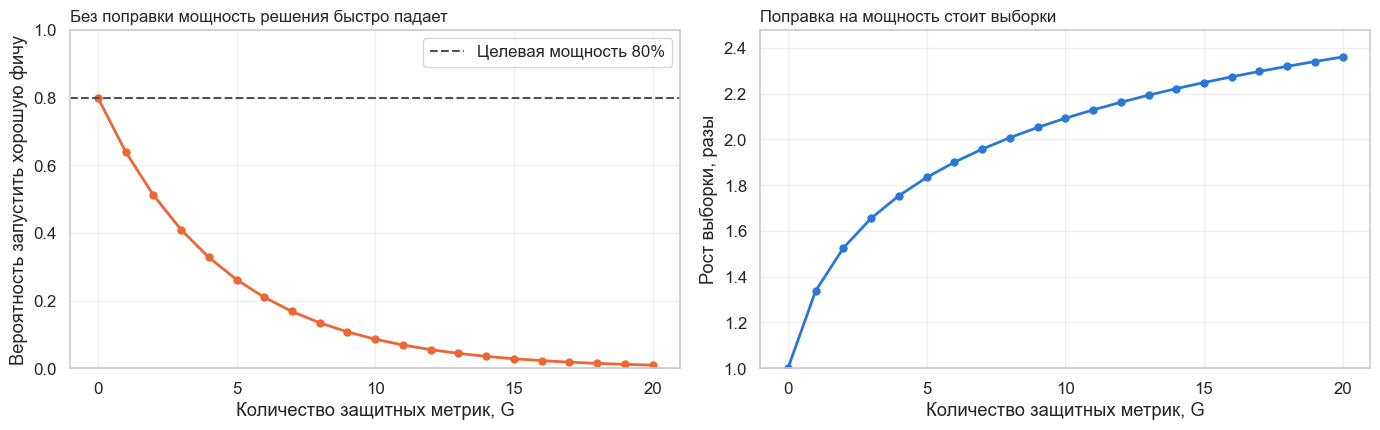

Мощность решения при G = 10 без поправки: 8.6%
Рост выборки при G = 10 с поправкой: в 2.09 раза


In [25]:
guardrails = np.arange(0, 21)
power_unadjusted = 0.8 ** (guardrails + 1)  # независимые метрики, мощность каждого теста 80%
beta_total = 0.2
z_alpha = stats.norm.ppf(1 - 0.05 / 2)
sample_multiplier = ((z_alpha + stats.norm.ppf(1 - beta_total / (guardrails + 1))) / (z_alpha + stats.norm.ppf(1 - beta_total))) ** 2

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(guardrails, power_unadjusted, color=NULL_COLOR, linewidth=2, marker='o', markersize=5)
axes[0].axhline(0.8, color=REFERENCE_COLOR, linestyle='--', linewidth=1.5, label='Целевая мощность 80%')
axes[0].set_ylim(0, 1)
axes[0].set_title('Без поправки мощность решения быстро падает', loc='left', fontsize=12)
axes[0].set_xlabel('Количество защитных метрик, G')
axes[0].set_ylabel('Вероятность запустить хорошую фичу')
axes[0].legend()

axes[1].plot(guardrails, sample_multiplier, color=REAL_COLOR, linewidth=2, marker='o', markersize=5)
axes[1].set_ylim(1, sample_multiplier.max() * 1.05)
axes[1].set_title('Поправка на мощность стоит выборки', loc='left', fontsize=12)
for ax in axes:
    ax.set_xticks(np.arange(0, 21, 5))
axes[1].set_xlabel('Количество защитных метрик, G')
axes[1].set_ylabel('Рост выборки, разы')

plt.tight_layout()
plt.show()

print(f"Мощность решения при G = 10 без поправки: {power_unadjusted[10]:.1%}")
print(f"Рост выборки при G = 10 с поправкой: в {sample_multiplier[10]:.2f} раза")

В полной версии правила Spotify добавляются ещё две проверки:

* **Метрики ухудшения (deterioration):** запуск блокируется, если любая метрика успеха, защитная метрика или дополнительная метрика ухудшения значимо упала.
* **Проверки качества (quality):** запуск блокируется, если эксперимент проведён некорректно. Например, есть sample ratio mismatch или различия групп до начала воздействия.

Для этих проверок авторы выделяют отдельный бюджет ошибки $\alpha_-$, делят его на число тестов и дополнительно уменьшают допустимую $\beta$. Подробности есть в [статье](https://arxiv.org/abs/2402.11609) и в [презентации по принятию решений на множестве метрик](https://docs.google.com/presentation/d/1v7PzCJONgs8wFC6D61VXhpF6vIv-lPNBfxbF0NQP1hg/edit?usp=sharing).

## Заключение

* Проверяя много гипотез, мы почти гарантированно получим ложные открытия, если не внесём поправки. Важно заранее определить семейство гипотез.
* FWER ограничивает вероятность хотя бы одной ошибки, а FDR ограничивает их среднюю долю. Выбор зависит от цены ошибки.
* По умолчанию для FWER используйте метод Холма, а для FDR используйте процедуру Бенджамини–Хохберга.
* Поправки снижают мощность, поэтому их нужно закладывать в размер выборки ещё на этапе дизайна.
* При неравных группах правило квадратного корня снижает MDE в сравнениях с контролем.
* Для решений по нескольким метрикам поправка следует из правила запуска: «хотя бы одна» требует поправки $\alpha$, а «все» требует поправки $\beta$.